<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment12_ProGAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount google drive and create folders

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import json
import random
import numpy as np
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN"
)

DATASET_DIR = PROJECT_DIR / "Dataset"
SOURCE_DIR = PROJECT_DIR / "Source_Code"
MODEL_DIR = PROJECT_DIR / "Saved_Models"
GENERATED_DIR = PROJECT_DIR / "Generated_Images"
RESULTS_DIR = PROJECT_DIR / "Results"
CURVES_DIR = RESULTS_DIR / "Training_Curves"
EVAL_DIR = RESULTS_DIR / "Evaluation"
REPORT_DIR = PROJECT_DIR / "Report"

for folder in [
    DATASET_DIR,
    SOURCE_DIR,
    MODEL_DIR,
    GENERATED_DIR / "32x32",
    GENERATED_DIR / "64x64",
    GENERATED_DIR / "128x128",
    CURVES_DIR,
    EVAL_DIR,
    REPORT_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project directory:", PROJECT_DIR)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is unavailable. Enable a GPU runtime before training.")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN
Device: cuda
GPU: Tesla T4


#Install and verify the required libraries

In [ ]:
%pip install -q torchvision matplotlib pandas tqdm

import torchvision
import matplotlib
import pandas as pd
from torchvision.datasets import CIFAR10

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Matplotlib:", matplotlib.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Matplotlib: 3.10.0
GPU available: True


#Download CIFAR-10 and select only cats

In [ ]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torchvision.utils import save_image
from PIL import Image
import matplotlib.pyplot as plt

CLASS_NAME = "cat"
CLASS_INDEX = 3

CIFAR_ROOT = DATASET_DIR / "CIFAR10"

# Download the original CIFAR-10 training and test sets.
cifar_train = CIFAR10(
    root=str(CIFAR_ROOT),
    train=True,
    download=True
)

cifar_test = CIFAR10(
    root=str(CIFAR_ROOT),
    train=False,
    download=True
)

# Select only cat samples.
train_indices = [
    i for i, label in enumerate(cifar_train.targets)
    if label == CLASS_INDEX
]

test_indices = [
    i for i, label in enumerate(cifar_test.targets)
    if label == CLASS_INDEX
]

print("Selected class:", CLASS_NAME)
print("Training cat images:", len(train_indices))
print("Test cat images:", len(test_indices))
print("Original image size:", cifar_train[0][0].size)

100%|██████████| 170M/170M [55:29<00:00, 51.2kB/s]


Selected class: cat
Training cat images: 5000
Test cat images: 1000
Original image size: (32, 32)


#Inspect sample cat images

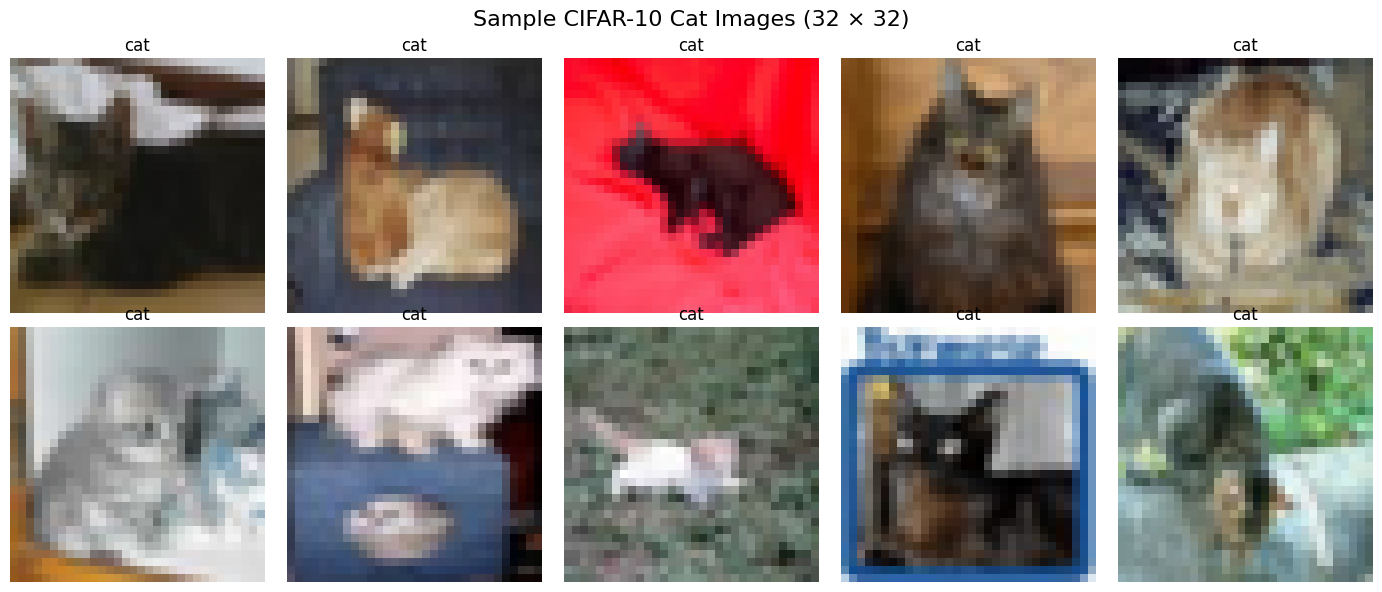

Sample figure saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/CIFAR10_Cat_Samples.png


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for ax, idx in zip(axes.flat, train_indices[:10]):
    image, label = cifar_train[idx]
    ax.imshow(image)
    ax.set_title(CLASS_NAME)
    ax.axis("off")

plt.suptitle(
    "Sample CIFAR-10 Cat Images (32 × 32)",
    fontsize=16
)
plt.tight_layout()

sample_path = RESULTS_DIR / "CIFAR10_Cat_Samples.png"
plt.savefig(sample_path, dpi=300, bbox_inches="tight")
plt.show()

print("Sample figure saved to:", sample_path)

#Prepare the training dataset

In [ ]:
class CIFAR10CatDataset(Dataset):
    def __init__(self, base_dataset, indices):
        self.base_dataset = base_dataset
        self.indices = indices

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=(0.5, 0.5, 0.5),
                std=(0.5, 0.5, 0.5)
            )
        ])

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image_index = self.indices[idx]
        image, _ = self.base_dataset[image_index]

        image = self.transform(image)

        return image


cat_train_dataset = CIFAR10CatDataset(
    cifar_train,
    train_indices
)

cat_test_dataset = CIFAR10CatDataset(
    cifar_test,
    test_indices
)

BATCH_SIZE = 32

train_loader = DataLoader(
    cat_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

test_loader = DataLoader(
    cat_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

real_batch = next(iter(train_loader))

print("Training dataset size:", len(cat_train_dataset))
print("Test dataset size:", len(cat_test_dataset))
print("Batch shape:", real_batch.shape)
print("Pixel range:", real_batch.min().item(), "to", real_batch.max().item())

Training dataset size: 5000
Test dataset size: 1000
Batch shape: torch.Size([32, 3, 32, 32])
Pixel range: -1.0 to 1.0


#ProGAN configuration

In [ ]:
import os
import time
import math
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.utils import save_image, make_grid


LATENT_DIM = 128
CHANNELS = {
    4: 256,
    8: 256,
    16: 128,
    32: 64,
    64: 32,
    128: 16
}

RESOLUTIONS = [32, 64, 128]


EPOCHS_PER_STAGE = {
    32: 10,
    64: 10,
    128: 10
}

BATCH_SIZES = {
    32: 32,
    64: 16,
    128: 8
}

LEARNING_RATE = 0.0001
BETAS = (0.0, 0.99)
LAMBDA_GP = 10.0
N_CRITIC = 1
FADE_IN_FRACTION = 0.5
SAMPLES_TO_SAVE = 25

print("Device:", DEVICE)
print("Progressive resolutions:", RESOLUTIONS)
print("Epochs per stage:", EPOCHS_PER_STAGE)
print("Batch sizes:", BATCH_SIZES)

Device: cuda
Progressive resolutions: [32, 64, 128]
Epochs per stage: {32: 10, 64: 10, 128: 10}
Batch sizes: {32: 32, 64: 16, 128: 8}


#ProGAN building blocks

In [ ]:
class PixelNorm(nn.Module):
    def __init__(self, epsilon=1e-8):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, x):
        return x / torch.sqrt(
            torch.mean(x ** 2, dim=1, keepdim=True) + self.epsilon
        )


class EqualizedConv2d(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        padding=0
    ):
        super().__init__()

        self.weight = nn.Parameter(
            torch.randn(
                out_channels,
                in_channels,
                kernel_size,
                kernel_size
            )
        )

        self.bias = nn.Parameter(
            torch.zeros(out_channels)
        )

        self.scale = math.sqrt(
            2.0 / (in_channels * kernel_size * kernel_size)
        )

        self.padding = padding

    def forward(self, x):
        return F.conv2d(
            x,
            self.weight * self.scale,
            bias=self.bias,
            padding=self.padding
        )


class EqualizedLinear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        self.weight = nn.Parameter(
            torch.randn(out_features, in_features)
        )
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.scale = math.sqrt(2.0 / in_features)

    def forward(self, x):
        return F.linear(
            x,
            self.weight * self.scale,
            self.bias
        )


class GenBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = EqualizedConv2d(
            in_channels, out_channels, 3, padding=1
        )
        self.conv2 = EqualizedConv2d(
            out_channels, out_channels, 3, padding=1
        )

        self.norm1 = PixelNorm()
        self.norm2 = PixelNorm()
        self.activation = nn.LeakyReLU(0.2)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        x = self.activation(self.conv1(x))
        x = self.norm1(x)
        x = self.activation(self.conv2(x))
        x = self.norm2(x)
        return x


class DiscBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = EqualizedConv2d(
            in_channels, in_channels, 3, padding=1
        )
        self.conv2 = EqualizedConv2d(
            in_channels, out_channels, 3, padding=1
        )
        self.activation = nn.LeakyReLU(0.2)

    def forward(self, x):
        x = self.activation(self.conv1(x))
        x = self.activation(self.conv2(x))
        x = F.avg_pool2d(x, 2)
        return x


class MinibatchStdDev(nn.Module):
    def forward(self, x):
        batch_size, _, height, width = x.shape

        if batch_size > 1:
            std = torch.sqrt(
                x.var(dim=0, unbiased=False) + 1e-8
            )
            mean_std = std.mean().reshape(1, 1, 1, 1)
            mean_std = mean_std.expand(
                batch_size, 1, height, width
            )
        else:
            mean_std = torch.zeros(
                batch_size, 1, height, width,
                device=x.device,
                dtype=x.dtype
            )

        return torch.cat([x, mean_std], dim=1)

#Progressive generator

In [ ]:
class ProGenerator(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.latent_dim = latent_dim

        self.initial = nn.Sequential(
            EqualizedLinear(latent_dim, CHANNELS[4] * 4 * 4),
            nn.LeakyReLU(0.2)
        )

        self.initial_conv = EqualizedConv2d(
            CHANNELS[4], CHANNELS[4], 3, padding=1
        )

        self.initial_norm = PixelNorm()
        self.activation = nn.LeakyReLU(0.2)

        # 4 -> 8 -> 16 -> 32 -> 64 -> 128
        resolutions = [4, 8, 16, 32, 64, 128]

        self.blocks = nn.ModuleList()
        self.to_rgb = nn.ModuleList()

        for old_res, new_res in zip(
            resolutions[:-1], resolutions[1:]
        ):
            self.blocks.append(
                GenBlock(
                    CHANNELS[old_res],
                    CHANNELS[new_res]
                )
            )

            self.to_rgb.append(
                EqualizedConv2d(
                    CHANNELS[new_res], 3, 1, padding=0
                )
            )

    def forward(self, z, stage=0, alpha=1.0):
        if stage not in [0, 1, 2]:
            raise ValueError("stage must be 0, 1, or 2")

        # Start at 4x4.
        x = self.initial(z)
        x = x.view(-1, CHANNELS[4], 4, 4)
        x = self.activation(self.initial_conv(x))
        x = self.initial_norm(x)

        # Build 8x8, 16x16 and 32x32.
        for block_index in range(3):
            x = self.blocks[block_index](x)

        # Stage 0: 32x32
        if stage == 0:
            return torch.tanh(self.to_rgb[2](x))

        # Stage 1: 64x64; Stage 2: 128x128.
        # Use the feature map at the previous resolution
        # to calculate the old RGB path.
        previous_rgb = self.to_rgb[2](x)

        current_block_index = 3

        x = self.blocks[current_block_index](x)
        new_rgb = self.to_rgb[current_block_index](x)

        if stage == 1:
            output = (
                alpha * new_rgb
                + (1.0 - alpha) * F.interpolate(
                    previous_rgb,
                    scale_factor=2,
                    mode="nearest"
                )
            )
            return torch.tanh(output)

        # Stage 2: continue from 64x64 to 128x128.
        previous_rgb_64 = new_rgb

        x = self.blocks[4](x)
        new_rgb_128 = self.to_rgb[4](x)

        output = (
            alpha * new_rgb_128
            + (1.0 - alpha) * F.interpolate(
                previous_rgb_64,
                scale_factor=2,
                mode="nearest"
            )
        )

        return torch.tanh(output)

#Progressive discriminator

In [ ]:
class ProDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        # to_feature indices correspond to resolutions
        # 8, 16, 32, 64 and 128.
        self.from_rgb = nn.ModuleList()
        self.blocks = nn.ModuleList()

        resolutions = [8, 16, 32, 64, 128]

        for res in resolutions:
            self.from_rgb.append(
                EqualizedConv2d(
                    3, CHANNELS[res], 1, padding=0
                )
            )

        # 128 -> 64 -> 32 -> 16 -> 8
        for res in [128, 64, 32, 16]:
            self.blocks.append(
                DiscBlock(CHANNELS[res], CHANNELS[res // 2])
            )

        self.minibatch_std = MinibatchStdDev()

        self.final_conv = EqualizedConv2d(
            CHANNELS[8] + 1, CHANNELS[8], 3, padding=1
        )

        self.final_linear = nn.Sequential(
            EqualizedLinear(CHANNELS[8] * 8 * 8, CHANNELS[8]),
            nn.LeakyReLU(0.2),
            EqualizedLinear(CHANNELS[8], 1)
        )

        self.activation = nn.LeakyReLU(0.2)

    def forward(self, image, stage=0, alpha=1.0):
        # stage 0: 32x32; stage 1: 64x64; stage 2: 128x128.
        if stage == 0:
            x = self.activation(self.from_rgb[2](image))

            # 32 -> 16 -> 8
            x = self.blocks[2](x)
            x = self.blocks[3](x)
        else:
            current_resolution = 32 * (2 ** stage)
            current_from_rgb_index = stage + 2

            x = self.activation(
                self.from_rgb[current_from_rgb_index](image)
            )

            # Fade-in: new high-resolution path versus previous path.
            x = self.blocks[2 - stage](x) if stage == 1 else self.blocks[0](x)

            downsampled_image = F.avg_pool2d(image, 2)
            old_path = self.activation(
                self.from_rgb[current_from_rgb_index - 1](
                    downsampled_image
                )
            )

            x = alpha * x + (1.0 - alpha) * old_path

            # Downsample remaining levels until 8x8.
            if stage == 1:
                x = self.blocks[3](x)
            elif stage == 2:
                x = self.blocks[1](x)
                x = self.blocks[2](x)
                x = self.blocks[3](x)

        x = self.minibatch_std(x)
        x = self.activation(self.final_conv(x))
        x = x.flatten(start_dim=1)
        return self.final_linear(x)

#Correct the discriminator's 64 x 64 path and verify shapes

In [ ]:
class ProDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.from_rgb = nn.ModuleList([
            EqualizedConv2d(3, CHANNELS[r], 1)
            for r in [8, 16, 32, 64, 128]
        ])

        # 128 -> 64 -> 32 -> 16 -> 8
        self.blocks = nn.ModuleList([
            DiscBlock(CHANNELS[128], CHANNELS[64]),
            DiscBlock(CHANNELS[64], CHANNELS[32]),
            DiscBlock(CHANNELS[32], CHANNELS[16]),
            DiscBlock(CHANNELS[16], CHANNELS[8]),
        ])

        self.minibatch_std = MinibatchStdDev()
        self.final_conv = EqualizedConv2d(
            CHANNELS[8] + 1, CHANNELS[8], 3, padding=1
        )
        self.final_linear = nn.Sequential(
            EqualizedLinear(CHANNELS[8] * 8 * 8, CHANNELS[8]),
            nn.LeakyReLU(0.2),
            EqualizedLinear(CHANNELS[8], 1)
        )
        self.activation = nn.LeakyReLU(0.2)

    def forward(self, image, stage=0, alpha=1.0):
        if stage == 0:
            x = self.activation(self.from_rgb[2](image))
            x = self.blocks[2](x)  # 32 -> 16
            x = self.blocks[3](x)  # 16 -> 8

        elif stage == 1:
            x = self.activation(self.from_rgb[3](image))
            x = self.blocks[1](x)  # 64 -> 32

            old_path = F.avg_pool2d(image, 2)
            old_path = self.activation(self.from_rgb[2](old_path))

            x = alpha * x + (1.0 - alpha) * old_path
            x = self.blocks[2](x)  # 32 -> 16
            x = self.blocks[3](x)  # 16 -> 8

        elif stage == 2:
            x = self.activation(self.from_rgb[4](image))
            x = self.blocks[0](x)  # 128 -> 64

            old_path = F.avg_pool2d(image, 2)
            old_path = self.activation(self.from_rgb[3](old_path))

            x = alpha * x + (1.0 - alpha) * old_path
            x = self.blocks[1](x)  # 64 -> 32
            x = self.blocks[2](x)  # 32 -> 16
            x = self.blocks[3](x)  # 16 -> 8

        else:
            raise ValueError("stage must be 0, 1, or 2")

        x = self.minibatch_std(x)
        x = self.activation(self.final_conv(x))
        x = x.flatten(start_dim=1)

        return self.final_linear(x)

#Check both network before training

In [ ]:
G = ProGenerator(LATENT_DIM).to(DEVICE)
D = ProDiscriminator().to(DEVICE)

G.eval()
D.eval()

with torch.no_grad():
    z = torch.randn(2, LATENT_DIM, device=DEVICE)

    for stage, resolution in enumerate([32, 64, 128]):
        fake_images = G(z, stage=stage, alpha=1.0)
        scores = D(fake_images, stage=stage, alpha=1.0)

        print(
            f"Stage {stage}: Resolution={resolution}x{resolution}, "
            f"Generated shape={tuple(fake_images.shape)}, "
            f"Discriminator shape={tuple(scores.shape)}"
        )

        assert fake_images.shape == (
            2, 3, resolution, resolution
        )

        assert scores.shape == (2, 1)

print("All architecture shape checks passed.")

Stage 0: Resolution=32x32, Generated shape=(2, 3, 32, 32), Discriminator shape=(2, 1)
Stage 1: Resolution=64x64, Generated shape=(2, 3, 64, 64), Discriminator shape=(2, 1)
Stage 2: Resolution=128x128, Generated shape=(2, 3, 128, 128), Discriminator shape=(2, 1)
All architecture shape checks passed.


#Gradient penalty for WGAN-GP

In [ ]:
def gradient_penalty(
    discriminator,
    real_images,
    fake_images,
    stage,
    alpha
):
    batch_size = real_images.size(0)

    epsilon = torch.rand(
        batch_size, 1, 1, 1,
        device=real_images.device
    )

    interpolated = (
        epsilon * real_images
        + (1.0 - epsilon) * fake_images
    ).requires_grad_(True)

    scores = discriminator(
        interpolated,
        stage=stage,
        alpha=alpha
    )

    gradients = torch.autograd.grad(
        outputs=scores,
        inputs=interpolated,
        grad_outputs=torch.ones_like(scores),
        create_graph=True,
        retain_graph=True
    )[0]

    gradients = gradients.reshape(batch_size, -1)

    gradient_norm = gradients.norm(2, dim=1)

    penalty = ((gradient_norm - 1.0) ** 2).mean()

    return penalty

#Save generated images at each resolution

In [ ]:
@torch.no_grad()
def save_generated_samples(
    generator,
    stage,
    resolution,
    num_images=25
):
    generator.eval()

    z = torch.randn(
        num_images, LATENT_DIM, device=DEVICE
    )

    fake_images = generator(
        z,
        stage=stage,
        alpha=1.0
    )

    # Convert [-1, 1] to [0, 1] for saving.
    fake_images = (fake_images.clamp(-1, 1) + 1) / 2

    output_dir = GENERATED_DIR / f"{resolution}x{resolution}"
    output_dir.mkdir(parents=True, exist_ok=True)

    grid = make_grid(
        fake_images.cpu(),
        nrow=5,
        padding=2
    )

    grid_path = output_dir / f"ProGAN_Cats_{resolution}x{resolution}_Grid.png"
    save_image(grid, grid_path)

    # Save individual generated images as well.
    for i, image in enumerate(fake_images):
        save_image(
            image.cpu(),
            output_dir / f"cat_{i + 1:03d}.png"
        )

    print(f"Saved image grid: {grid_path}")
    generator.train()

    return grid_path

#Progressive training loop

In [ ]:
from tqdm.auto import tqdm

def make_stage_loader(resolution):
    transform = transforms.Compose([
        transforms.Resize(
            (resolution, resolution),
            interpolation=transforms.InterpolationMode.BICUBIC
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.5, 0.5, 0.5),
            std=(0.5, 0.5, 0.5)
        )
    ])

    class ResizedCatDataset(Dataset):
        def __init__(self, base_dataset):
            self.base_dataset = base_dataset

        def __len__(self):
            return len(self.base_dataset)

        def __getitem__(self, index):
            # The original dataset returns normalized 32x32 tensors.
            # Convert back to PIL before applying the new resolution.
            img = self.base_dataset.base_dataset[
                self.base_dataset.indices[index]
            ][0]
            return transform(img)

    return DataLoader(
        ResizedCatDataset(cat_train_dataset),
        batch_size=BATCH_SIZES[resolution],
        shuffle=True,
        drop_last=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )


def train_progan():
    generator = ProGenerator(LATENT_DIM).to(DEVICE)
    discriminator = ProDiscriminator().to(DEVICE)

    optimizer_g = torch.optim.Adam(
        generator.parameters(),
        lr=LEARNING_RATE,
        betas=BETAS
    )
    optimizer_d = torch.optim.Adam(
        discriminator.parameters(),
        lr=LEARNING_RATE,
        betas=BETAS
    )

    history = []
    global_step = 0

    for stage, resolution in enumerate(RESOLUTIONS):
        print(f"\n{'=' * 60}")
        print(f"Training at {resolution}x{resolution}")
        print(f"{'=' * 60}")

        loader = make_stage_loader(resolution)
        steps_per_epoch = len(loader)

        if steps_per_epoch == 0:
            raise RuntimeError(
                f"No full batches at resolution {resolution}. "
                "Reduce its batch size."
            )

        total_steps = EPOCHS_PER_STAGE[resolution] * steps_per_epoch
        fade_steps = max(1, int(total_steps * FADE_IN_FRACTION))

        for epoch in range(EPOCHS_PER_STAGE[resolution]):
            generator.train()
            discriminator.train()

            progress = tqdm(
                loader,
                desc=f"{resolution}x{resolution} Epoch {epoch + 1}"
            )

            epoch_g_loss = []
            epoch_d_loss = []

            for real_images in progress:
                real_images = real_images.to(DEVICE)
                batch_size = real_images.size(0)

                alpha = min(1.0, global_step / fade_steps) if stage > 0 else 1.0

                # -------------------------
                # Train Discriminator
                # -------------------------
                optimizer_d.zero_grad(set_to_none=True)

                z = torch.randn(
                    batch_size, LATENT_DIM, device=DEVICE
                )

                with torch.no_grad():
                    fake_images = generator(
                        z,
                        stage=stage,
                        alpha=alpha
                    )

                real_scores = discriminator(
                    real_images,
                    stage=stage,
                    alpha=alpha
                )
                fake_scores = discriminator(
                    fake_images,
                    stage=stage,
                    alpha=alpha
                )

                gp = gradient_penalty(
                    discriminator,
                    real_images,
                    fake_images,
                    stage,
                    alpha
                )

                d_loss = (
                    fake_scores.mean()
                    - real_scores.mean()
                    + LAMBDA_GP * gp
                )

                d_loss.backward()
                optimizer_d.step()

                # -------------------------
                # Train Generator
                # -------------------------
                optimizer_g.zero_grad(set_to_none=True)

                z = torch.randn(
                    batch_size, LATENT_DIM, device=DEVICE
                )

                generated = generator(
                    z,
                    stage=stage,
                    alpha=alpha
                )

                generated_scores = discriminator(
                    generated,
                    stage=stage,
                    alpha=alpha
                )

                g_loss = -generated_scores.mean()

                g_loss.backward()
                optimizer_g.step()

                global_step += 1

                epoch_g_loss.append(g_loss.item())
                epoch_d_loss.append(d_loss.item())

                progress.set_postfix({
                    "D_loss": f"{d_loss.item():.3f}",
                    "G_loss": f"{g_loss.item():.3f}",
                    "alpha": f"{alpha:.2f}"
                })

            mean_g = float(np.mean(epoch_g_loss))
            mean_d = float(np.mean(epoch_d_loss))

            history.append({
                "resolution": resolution,
                "stage": stage,
                "epoch": epoch + 1,
                "generator_loss": mean_g,
                "discriminator_loss": mean_d
            })

            print(
                f"Epoch {epoch + 1}/{EPOCHS_PER_STAGE[resolution]} | "
                f"G loss: {mean_g:.4f} | D loss: {mean_d:.4f}"
            )

        # Save a checkpoint and sample grid after each stage.
        checkpoint_path = MODEL_DIR / f"ProGAN_CIFAR10_Cat_{resolution}x{resolution}.pth"

        torch.save({
            "resolution": resolution,
            "stage": stage,
            "latent_dim": LATENT_DIM,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "optimizer_g_state_dict": optimizer_g.state_dict(),
            "optimizer_d_state_dict": optimizer_d.state_dict(),
            "history": history,
        }, checkpoint_path)

        print("Checkpoint saved:", checkpoint_path)

        save_generated_samples(
            generator,
            stage=stage,
            resolution=resolution,
            num_images=SAMPLES_TO_SAVE
        )

    history_df = pd.DataFrame(history)
    history_path = CURVES_DIR / "ProGAN_Training_History.csv"
    history_df.to_csv(history_path, index=False)

    return generator, discriminator, history_df


# Start training.
generator, discriminator, history_df = train_progan()

print("\nTraining completed.")
print("Training history:", CURVES_DIR / "ProGAN_Training_History.csv")


Training at 32x32


32x32 Epoch 1:   0%|          | 0/156 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1/10 | G loss: 1.6319 | D loss: 1.9069


32x32 Epoch 2:   0%|          | 0/156 [00:00<?, ?it/s]

...

Epoch 8/10 | G loss: -58.8090 | D loss: -4.2855


128x128 Epoch 9:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 9/10 | G loss: -44.3683 | D loss: -3.1006


128x128 Epoch 10:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 10/10 | G loss: -22.5571 | D loss: -4.8866
Checkpoint saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Saved_Models/ProGAN_CIFAR10_Cat_128x128.pth
Saved image grid: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Generated_Images/128x128/ProGAN_Cats_128x128_Grid.png

Training completed.
Training history: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Training_Curves/ProGAN_Training_History.csv


#Plot the training losses

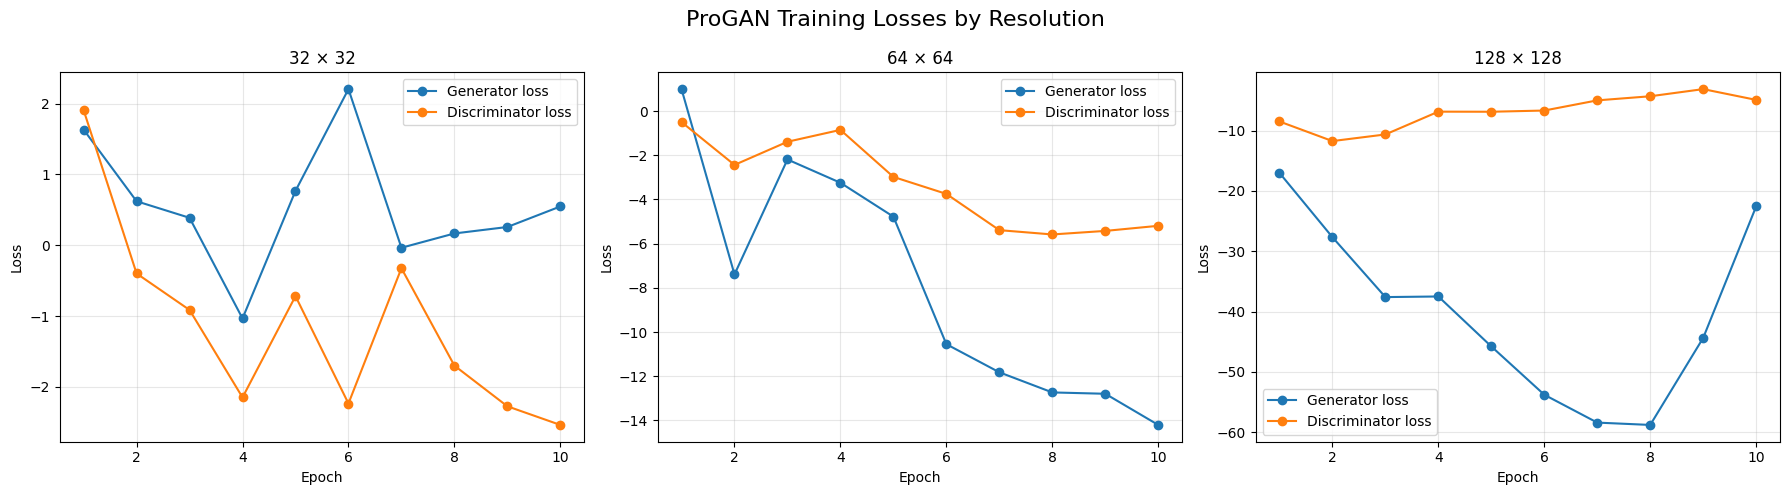

Loss plot saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Training_Curves/ProGAN_Training_Losses.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, resolution in zip(axes, RESOLUTIONS):
    subset = history_df[
        history_df["resolution"] == resolution
    ]

    ax.plot(
        subset["epoch"],
        subset["generator_loss"],
        marker="o",
        label="Generator loss"
    )

    ax.plot(
        subset["epoch"],
        subset["discriminator_loss"],
        marker="o",
        label="Discriminator loss"
    )

    ax.set_title(f"{resolution} × {resolution}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("ProGAN Training Losses by Resolution", fontsize=16)
plt.tight_layout()

loss_path = CURVES_DIR / "ProGAN_Training_Losses.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss plot saved:", loss_path)

#Display generated images from all stages

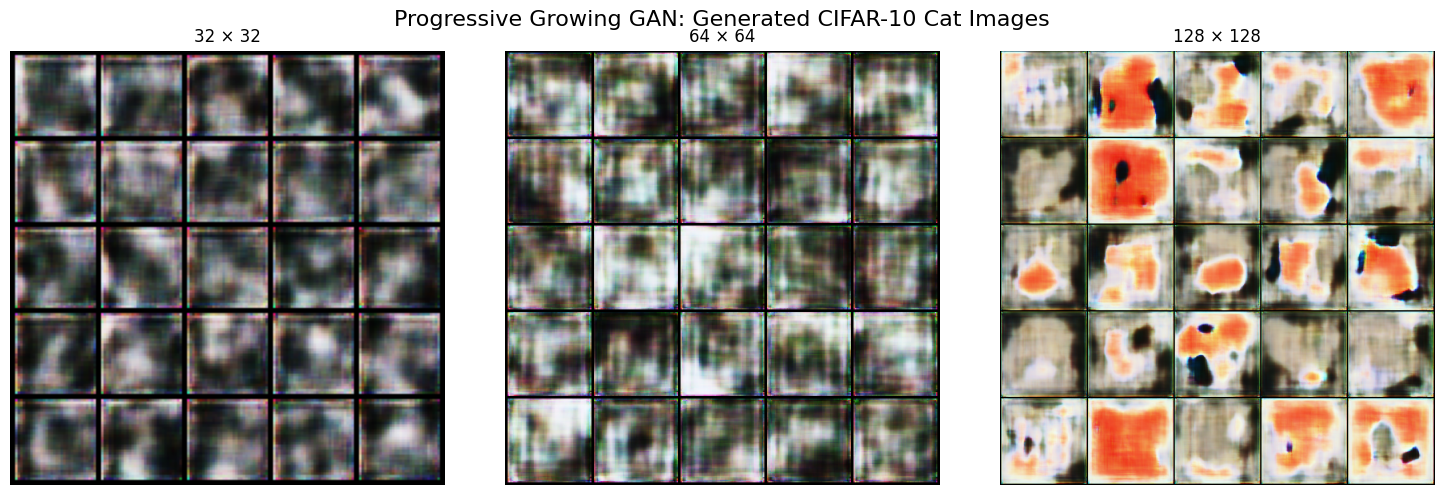

Resolution comparison saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Evaluation/Progressive_Resolution_Comparison.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, resolution in zip(axes, RESOLUTIONS):
    image_path = (
        GENERATED_DIR
        / f"{resolution}x{resolution}"
        / f"ProGAN_Cats_{resolution}x{resolution}_Grid.png"
    )

    grid_image = Image.open(image_path).convert("RGB")

    ax.imshow(grid_image)
    ax.set_title(f"{resolution} × {resolution}")
    ax.axis("off")

plt.suptitle(
    "Progressive Growing GAN: Generated CIFAR-10 Cat Images",
    fontsize=16
)
plt.tight_layout()

comparison_path = EVAL_DIR / "Progressive_Resolution_Comparison.png"
plt.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()

print("Resolution comparison saved:", comparison_path)

#Verify all generated images and checkpoints

In [ ]:
from pathlib import Path
from PIL import Image
import json
import pandas as pd

verification = []

for resolution in [32, 64, 128]:
    image_dir = GENERATED_DIR / f"{resolution}x{resolution}"
    grid_path = image_dir / f"ProGAN_Cats_{resolution}x{resolution}_Grid.png"
    checkpoint_path = MODEL_DIR / f"ProGAN_CIFAR10_Cat_{resolution}x{resolution}.pth"

    individual_images = list(image_dir.glob("cat_*.png"))

    grid_exists = grid_path.exists()
    checkpoint_exists = checkpoint_path.exists()

    dimensions_ok = False
    if individual_images:
        with Image.open(individual_images[0]) as img:
            dimensions_ok = img.size == (resolution, resolution)

    verification.append({
        "Resolution": f"{resolution}x{resolution}",
        "Individual Images": len(individual_images),
        "Grid Exists": grid_exists,
        "Checkpoint Exists": checkpoint_exists,
        "Image Dimensions Correct": dimensions_ok
    })

verification_df = pd.DataFrame(verification)

display(verification_df)

verification_path = EVAL_DIR / "Output_Verification.csv"
verification_df.to_csv(verification_path, index=False)

print("Verification report saved:", verification_path)

,Resolution,Individual Images,Grid Exists,Checkpoint Exists,Image Dimensions Correct
0,32x32,25,True,True,True
1,64x64,25,True,True,True
2,128x128,25,True,True,True


Verification report saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Evaluation/Output_Verification.csv


#Compare the generated images visually

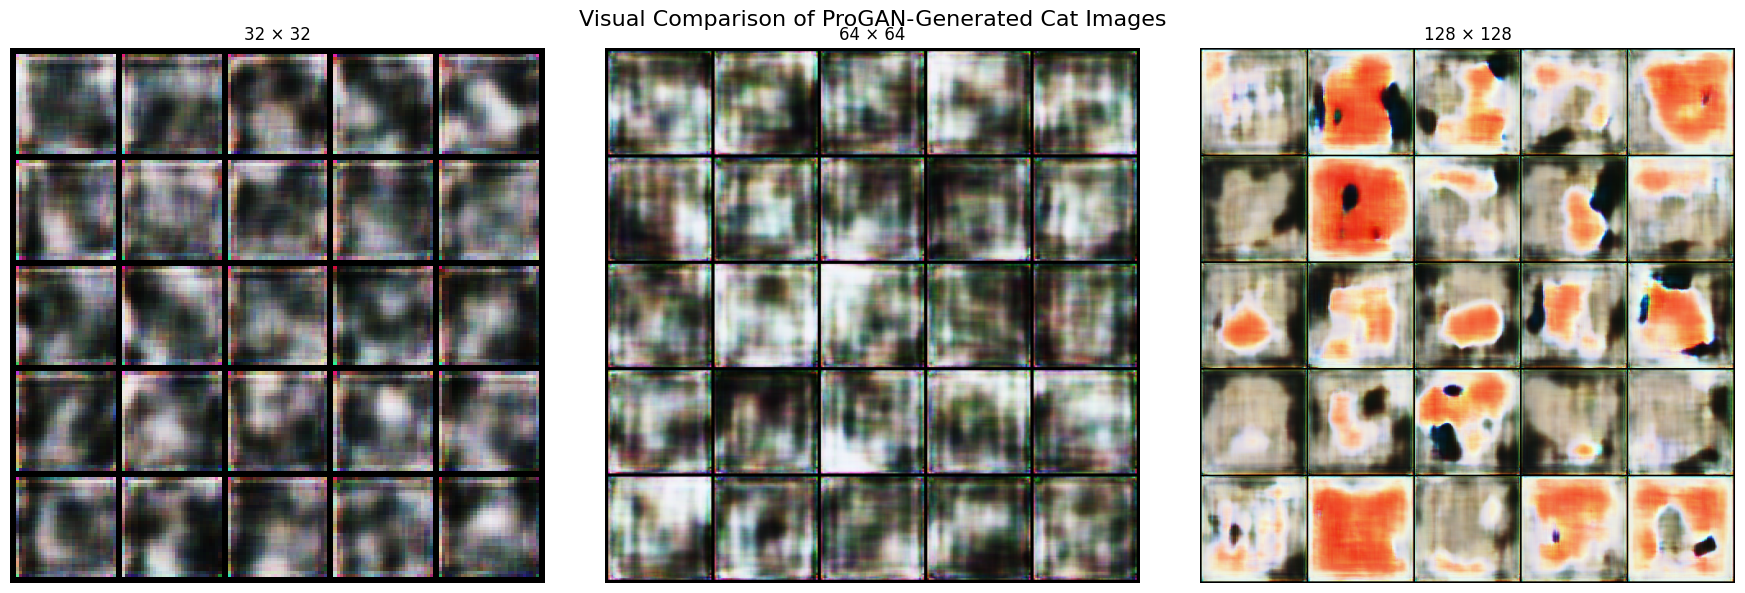

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Evaluation/Progressive_Resolution_Comparison.png


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, resolution in zip(axes, [32, 64, 128]):
    grid_path = (
        GENERATED_DIR
        / f"{resolution}x{resolution}"
        / f"ProGAN_Cats_{resolution}x{resolution}_Grid.png"
    )

    if grid_path.exists():
        ax.imshow(Image.open(grid_path).convert("RGB"))
        ax.set_title(f"{resolution} × {resolution}")
    else:
        ax.text(
            0.5, 0.5, "Image grid not found",
            ha="center", va="center"
        )
        ax.set_title(f"{resolution} × {resolution}")

    ax.axis("off")

plt.suptitle(
    "Visual Comparison of ProGAN-Generated Cat Images",
    fontsize=16
)
plt.tight_layout()

comparison_path = (
    EVAL_DIR / "Progressive_Resolution_Comparison.png"
)
plt.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", comparison_path)

#Summarize training results

In [ ]:
history_path = CURVES_DIR / "ProGAN_Training_History.csv"

history_df = pd.read_csv(history_path)

summary = (
    history_df.groupby("resolution")
    .agg(
        Epochs=("epoch", "count"),
        Final_Generator_Loss=("generator_loss", "last"),
        Final_Discriminator_Loss=("discriminator_loss", "last"),
        Minimum_Generator_Loss=("generator_loss", "min"),
        Minimum_Discriminator_Loss=("discriminator_loss", "min")
    )
    .reset_index()
)

display(summary.round(4))

summary_path = EVAL_DIR / "Training_Results_Summary.csv"
summary.to_csv(summary_path, index=False)

print("Saved:", summary_path)

,resolution,Epochs,Final_Generator_Loss,Final_Discriminator_Loss,Minimum_Generator_Loss,Minimum_Discriminator_Loss
0,32,10,0.5469,-2.5373,-1.0338,-2.5373
1,64,10,-14.2037,-5.1937,-14.2037,-5.5847
2,128,10,-22.5571,-4.8866,-58.8090,-11.7195


Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Evaluation/Training_Results_Summary.csv


# FID evaluation (Optional)

In [ ]:
%pip install -q torchmetrics torch-fidelity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 9.9 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn.functional as F
from torchvision.utils import save_image
from torchmetrics.image.fid import FrechetInceptionDistance
from tqdm.auto import tqdm

def calculate_fid_for_resolution(
    resolution,
    num_samples=500,
    batch_size=32
):
    device = DEVICE

    checkpoint_path = (
        MODEL_DIR
        / f"ProGAN_CIFAR10_Cat_{resolution}x{resolution}.pth"
    )

    if not checkpoint_path.exists():
        print(f"Skipping {resolution}x{resolution}: checkpoint missing.")
        return None

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model = ProGenerator(LATENT_DIM).to(device)
    model.load_state_dict(checkpoint["generator_state_dict"])
    model.eval()

    stage = checkpoint["stage"]

    fid = FrechetInceptionDistance(
        feature=2048,
        normalize=True
    ).to(device)

    # Real images: use only the held-out cat test set.
    real_count = min(num_samples, len(cat_test_dataset))

    real_loader = DataLoader(
        cat_test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2
    )

    processed = 0

    with torch.no_grad():
        for real in real_loader:
            if processed >= real_count:
                break

            real = real.to(device)

            real = F.interpolate(
                real,
                size=(resolution, resolution),
                mode="bilinear",
                align_corners=False
            )

            real = ((real.clamp(-1, 1) + 1) / 2).clamp(0, 1)

            # FID's Inception network accepts RGB images;
            # resize to 299x299 for its feature extractor.
            real = F.interpolate(
                real,
                size=(299, 299),
                mode="bilinear",
                align_corners=False
            )

            fid.update(real, real=True)
            processed += real.size(0)

    # Generated images
    generated_count = 0

    with torch.no_grad():
        while generated_count < real_count:
            current_batch = min(
                batch_size,
                real_count - generated_count
            )

            z = torch.randn(
                current_batch,
                LATENT_DIM,
                device=device
            )

            fake = model(z, stage=stage, alpha=1.0)
            fake = ((fake.clamp(-1, 1) + 1) / 2).clamp(0, 1)

            fake = F.interpolate(
                fake,
                size=(299, 299),
                mode="bilinear",
                align_corners=False
            )

            fid.update(fake, real=False)
            generated_count += current_batch

    score = float(fid.compute().item())

    print(
        f"FID at {resolution}x{resolution}: "
        f"{score:.4f} (using {processed} real and "
        f"{generated_count} generated images)"
    )

    return {
        "resolution": resolution,
        "real_samples": processed,
        "generated_samples": generated_count,
        "FID": score
    }


fid_results = []

for resolution in [32, 64, 128]:
    try:
        result = calculate_fid_for_resolution(
            resolution=resolution,
            num_samples=500
        )

        if result is not None:
            fid_results.append(result)

    except Exception as e:
        print(f"FID failed at {resolution}x{resolution}: {e}")
        print("Keep the visual evaluation and report this limitation.")

if fid_results:
    fid_df = pd.DataFrame(fid_results)
    fid_path = EVAL_DIR / "FID_Results.csv"
    fid_df.to_csv(fid_path, index=False)

    display(fid_df)
    print("FID results saved:", fid_path)
else:
    print("No FID scores were produced.")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 231MB/s]


FID at 32x32: 296.6114 (using 512 real and 500 generated images)
FID at 64x64: 388.6216 (using 512 real and 500 generated images)
FID at 128x128: 335.7007 (using 512 real and 500 generated images)


,resolution,real_samples,generated_samples,FID
0,32,512,500,296.611420
1,64,512,500,388.621613
2,128,512,500,335.700653


FID results saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Results/Evaluation/FID_Results.csv


#Save an experiment summary

In [ ]:
experiment_summary = {
    "assignment": "Assignment-12: Progressive Growing GAN",
    "dataset": "CIFAR-10",
    "selected_class": "cat",
    "class_index": 3,
    "training_images": len(cat_train_dataset),
    "test_images": len(cat_test_dataset),
    "resolutions": [32, 64, 128],
    "latent_dimension": LATENT_DIM,
    "epochs_per_stage": EPOCHS_PER_STAGE,
    "batch_sizes": BATCH_SIZES,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "betas": list(BETAS),
    "adversarial_loss": "Wasserstein loss with gradient penalty",
    "gradient_penalty_weight": LAMBDA_GP,
    "random_seed": SEED,
    "device": str(DEVICE),
    "notes": (
        "CIFAR-10 images are natively 32x32. "
        "Higher-resolution training stages use resized real images."
    )
}

summary_json = REPORT_DIR / "Experiment_Summary.json"

with open(summary_json, "w") as f:
    json.dump(experiment_summary, f, indent=4)

print("Experiment summary saved:", summary_json)

Experiment summary saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment12_ProGAN/Report/Experiment_Summary.json
